In [ ]:
# ignore all warnings
import warnings
warnings.filterwarnings('ignore')

In [ ]:
from dask.distributed import Client, LocalCluster

cluster = LocalCluster()
client = Client(cluster)

In [ ]:
client

In [10]:
import numpy as np
import dask.array as da
from ase.data import covalent_radii
from scipy.ndimage import zoom
from skimage.measure import regionprops
def get_rag_from_atoms(mat_atoms, spacing = 0.5, block_size=20000, mask_thickness=1.5 , bins = np.linspace(0,30, 50)):
    try:
        radii = covalent_radii[mat_atoms.get_atomic_numbers()]
        grid = mgr.dgrid_from_atoms(mat_atoms, radii=radii, spacing =spacing, block_size=block_size)
        grid = da.from_array(zoom(grid.compute(), 2), chunks=(20,20,20))
        regions, maxima = mgr.regions_from_dgrid(grid.compute(), mask_thickness=mask_thickness, h=0.25)
        rag2 = mgr.get_rag_from_regions_and_grid(regions, grid.compute(),mat_atoms,maxima)
        rag2.graph['name'] = mat_atoms.info['name']
        pbc_groups = mgr.get_periodic_map(regions=regions, maxima=maxima, maxima_radii=grid.compute()[tuple(maxima.T)], return_conn=True, wall_thickness=4)
        props = regionprops(regions)
        rag2 = mgr.add_psd_to_rag_with_pbc(rag = rag2, props = props, pbc_groups= pbc_groups, bins = bins, ase_atoms = mat_atoms, shape =regions.shape)
        rag2 = mgr.add_clustering_to_rag(rag2)
        return rag2
    except: 
        return 'NaN'

In [11]:
from dask import delayed
graphs = []
for a in iza_atoms:
    graphs.append(delayed(get_rag_from_atoms)(a))

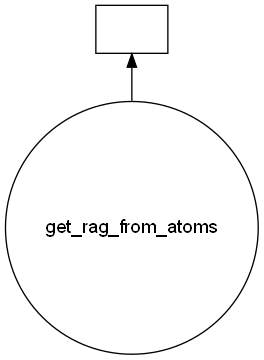

In [12]:
graphs[0].visualize()

In [ ]:
futures = client.persist(graphs)
from dask.distributed import progress
progress(futures)


In [ ]:
#check how many of them calculations failed
iza_graphs = [g.compute() for g in graphs]
np.where([i=='NaN' for i in iza_graphs])

In [ ]:
import pickle

with open('iza_graphs.pkl', 'wb') as f:
    pickle.dump(iza_graphs, f)

In [ ]:
def compute_and_plot(mat_atoms, spacing = 0.5, block_size=50000, mask_thickness=1.5 , bins = np.linspace(0,50, 50)):
    import numpy as np
    import dask.array as da
    from ase.data import covalent_radii
    from scipy.ndimage import zoom
    from skimage.measure import regionprops
    try:
        # compute stuff
        radii = covalent_radii[mat_atoms.get_atomic_numbers()]
        grid = mgr.dgrid_from_atoms(mat_atoms, radii=radii, spacing =spacing, block_size=block_size)
        grid = da.from_array(zoom(grid.compute(), 2), chunks=(20,20,20))
        regions, maxima = mgr.regions_from_dgrid(grid.compute(), mask_thickness=mask_thickness, h=0.25)
        rag2 = mgr.get_rag_from_regions_and_grid(regions, grid.compute(),mat_atoms,maxima)
        rag2.graph['name'] = mat_atoms.info['name']
        pbc_groups = mgr.get_periodic_map(regions=regions, maxima=maxima, maxima_radii=grid.compute()[tuple(maxima.T)], return_conn=True, wall_thickness=4)
        props = regionprops(regions)
        rag2 = mgr.add_psd_to_rag_with_pbc(rag = rag2, props = props, pbc_groups= pbc_groups, bins = bins, ase_atoms = mat_atoms, shape =regions.shape)
        rag2 = mgr.add_clustering_to_rag(rag2)
        
        # plot stuff
        import plotly.graph_objects as go
        import plotly.io as pio 
        pio.renderers.default = "browser"

        mat_updated = mgr.update_with_covalent_bonds(mat_atoms)
        frame_trace = mgr.plot_framework_as_mesh(mat_updated, show_rings=False, stylize=True)
        rag_trace=mgr.plot_rag(rag2,plot_with='maxima', name='p-graph') 
        surface_trace=mgr.plot_surface_dgrid(grid.compute(), 1.75, select='all',ase_atoms=mat_updated,region_labels=regions, stylize=True)
        # surface_trace=mgr.plot_surface_dgrid(grid.compute(), 1.75, select='all',ase_atoms=mat_updated,region_labels=regions_pbc, stylize=True)
        # surface_trace=mgr.plot_surface_dgrid(grid.compute(), 1.75, select=list(pbc_groups[4]),ase_atoms=mat_updated,region_labels=regions, stylize=True)
        cell_trace=mgr.plot_cell(mat_updated)
        maxima_trace = mgr.plot_maxima(maxima = maxima, dgrid = grid.compute(),ase_atoms =mat_updated)

        # fig = go.Figure(data=[*frame_trace,rag_trace,surface_trace,cell_trace,maxima_trace]).update(layout=mgr.white_layout).show()
        fig1 = go.Figure(data=[*frame_trace,rag_trace, surface_trace,cell_trace,maxima_trace]).update(layout=mgr.white_layout)
        fig2 = go.Figure(data=mgr.plot_psds(rag2, pbc_groups))
        return pbc_groups, fig1, fig2
    except: 
        return 'NaN'

In [ ]:
import random 
# mat_atoms = random.choice(iza_atoms)
mat_atoms = iza_atoms[195]

pbc_groups, fig1, fig2 = compute_and_plot(mat_atoms)
pbc_groups
fig1.show(), fig2.show()

In [ ]:
pbc_groups

In [ ]:
mat_atoms.info

In [ ]:
df[df['name']=='TUN-0']

In [ ]:
iza_atoms[202].info

In [ ]:
def add_clustering_to_rag(rag2, distance_threshold = 0.40, return_cluster_obj = False):
    """
    > We take the RAG, get the PSD data for each node, and then use agglomerative clustering to cluster
    the nodes.
    
    :param rag2: the RAG object
    :param distance_threshold: The linkage distance at which to cut the dendrogram to determine the
    clusters
    :param return_cluster_obj: if True, returns the clustering object as well as the rag, defaults to
    False (optional)
    :return: The rag2 object with the cluster labels added to the nodes.
    """
    
    import numpy as np 
    import networkx as nx 

    # *  get the data array, while reordering to match the node order   
    X = np.vstack(dict(sorted(nx.get_node_attributes(rag2, 'psd_y_pbc').items())).values())

    # * scale each row by the max value in that row
    from sklearn.preprocessing import MinMaxScaler
    X = MinMaxScaler().fit_transform(X)
    
    # * do the clustering using agglomerative clustering 
    from sklearn.cluster import AgglomerativeClustering 
    if len(X) > 1:
        clustering = AgglomerativeClustering(compute_full_tree=True, linkage='single', distance_threshold = distance_threshold, n_clusters=None).fit(X)
        
        #* Add the clustering info to rag
        for i in rag2.nodes():
            rag2.nodes[i]['cluster'] = str(clustering.labels_[i-1])
        if return_cluster_obj:
            return (rag2, clustering)
        else:
            return rag2
    elif len(X) == 1:
        # rag2.nodes[1]['cluster'] = '1'
        nx.set_node_attributes(rag2, '1', 'cluster')
        print('Only one node in the graph')
        return rag2
    else: 
        raise ValueError('No PSD with PBC data in the RAG (pore graph). Call add_pbc_psd_to_rag() first.')
        

In [ ]:
x= np.random.random((10,3))
from sklearn.preprocessing import MinMaxScaler 
MinMaxScaler().fit_transform(x)

In [3]:
import dtale
df1=df[['void_fraction', 'lcd', 'pld', 'surface_area_m2g', 'surface_area_m2cm3']]
dtale.show(df1).open_browser()

In [1]:
import sys
import os

import numpy as np
# * Put your path here
path_to_mgr = os.path.abspath('c:/Users/Arun Gopalan/OneDrive - The University of Manchester/my_cloned_repos/mofography')

sys.path.append(path_to_mgr)

import mofography as mgr 
#%%
# read the iza database and the list of ase atoms


import pandas as pd
import pickle 


df = pd.read_feather('C:/Users/Arun Gopalan/OneDrive - The University of Manchester/my_cloned_repos/mofography/examples/iza_df.feather')
iza_atoms = pickle.load(open('C:/Users/Arun Gopalan/OneDrive - The University of Manchester/my_cloned_repos/mofography/examples/iza_atoms_list.pkl','rb'))


In [3]:
import numpy as np
import ase
import dask.array as da
from ase.data import covalent_radii
from scipy.ndimage import zoom
from skimage.measure import regionprops
import random
spacing = 0.5
wall_thickness =1.0
mask_thickness =1.5
bins = np.linspace(0,30, 50)
block_size = 20000
a, b, c, =1,1,1 
# mat_atoms = iza_atoms[195]
chosen = random.choice(range(len(iza_atoms)))
# chosen = 195 #random.choice(range(len(iza_atoms)))
# chosen=76
# chosen=89
# chosen = 64
chosen = 15
# chosen = 21
# chosen = 182
print(chosen)
mat_atoms = iza_atoms[chosen]
radii = covalent_radii[mat_atoms.get_atomic_numbers()]
grid = mgr.dgrid_from_atoms(mat_atoms, radii=radii, spacing =spacing, block_size=block_size)
# bins = np.linspace(0,grid.compute().max(), 50)
mat_atoms = ase.build.make_supercell(mat_atoms, [[a,0,0],[0,b,0],[0,0,
c]])
grid = da.from_array(np.tile(grid.compute(), [a,b,c]))
grid = da.from_array(zoom(grid.compute(), 2,mode='grid-wrap', order=3 ), chunks=(40,40,40))
regions, maxima = mgr.regions_from_dgrid(grid.compute(), mask_thickness=mask_thickness, compactness=0.001, h=0.2)
maxima_radii = grid.compute()[tuple(maxima.T)]
# pbc_groups = mgr.apply_pbc(regions, maxima, maxima_radii, wall_thickness=1, return_conn=True)
pbc_groups = mgr.apply_pbc2(regions, maxima, maxima_radii,mat_atoms, wall_thickness=wall_thickness, return_conn=True, minimum_overlap_fraction=0.5)
rag2 = mgr.get_rag_from_regions_and_grid(regions, grid.compute(),mat_atoms,maxima)
# rag2.graph['name'] = mat_atoms.info['name']
# pbc_groups = mgr.get_periodic_map(regions=regions, maxima=maxima, maxima_radii=grid.compute()[tuple(maxima.T)], return_conn=True, wall_thickness=4)
props = regionprops(regions)
rag2 = mgr.add_psd_to_rag( rag2,region_props=props,  bins = bins, ase_atoms = mat_atoms, shape =regions.shape)
rag2 = mgr.add_psd_to_rag_with_pbc(rag = rag2, props = props, pbc_groups= pbc_groups, bins = bins, ase_atoms = mat_atoms, shape =regions.shape)
# connections = mgr.get_connections_for_rag(rag2, regions, maxima, mat_atoms, grid.compute())
# rag2 = mgr.add_clustering_to_rag(rag2, affinity='euclidean', linkage='single', distance_threshold=0.25, no_pbc=False)
rag2 = mgr.add_clustering_to_rag(rag2, kwargs_cluster=dict(distance_threshold=0.25, kernel = 'linear'))#, affinity='euclidean', linkage='single', distance_threshold=0.25, no_pbc=False)
cluster_regions2 = np.zeros(regions.shape)
for r in range(1,regions.max()+1):
    # cluster_regions[np.where(regions==r)] = cluster_map[r]
    cluster_regions2[np.where(regions==r)] = int(rag2.nodes[r]['cluster'])


15


c:\Users\Arun Gopalan\OneDrive - The University of Manchester\my_cloned_repos\mofography\mofography\compute.py:352: UserWarning: Some maxima excluded as they fell inside the mask_thickness
  warnings.warn('Some maxima excluded as they fell inside the mask_thickness')


In [5]:
import plotly.graph_objects as go
import plotly.io as pio 
import plotly.express as px 
cscale = px.colors.qualitative.Pastel
pio.renderers.default = "browser"
# pmap= mgr.get_periodic_map(regions=regions, maxima=maxima, maxima_radii=grid.compute()[tuple(maxima.T)], return_conn=False, wall_thickness=4)
# regions_pbc  = np.vectorize(pmap.get)(regions)
regions_pbc =mgr.apply_pbc2(regions, maxima, maxima_radii,mat_atoms, wall_thickness=wall_thickness, return_conn=False, minimum_overlap_fraction=0.5)
mat_updated = mgr.update_with_covalent_bonds(mat_atoms)
frame_trace = mgr.plot_framework_as_mesh(mat_updated, show_rings=False, stylize=True)
# rag_trace=mgr.plot_rag(rag2,plot_with='maxima', name='p-graph') 
surface_trace=mgr.plot_surface_dgrid(grid.compute(), 1.65, select='all',ase_atoms=mat_updated,region_labels=regions, cscale =cscale, stepsize=1, stylize=True)
surface_trace_pbc=mgr.plot_surface_dgrid(grid.compute(), 1.75, select='all',ase_atoms=mat_updated,region_labels=regions_pbc, cscale =cscale, stepsize=2, stylize=True)
# surface_trace_sel=mgr.plot_surface_dgrid(grid.compute(), 1.75, select=list(pbc_groups[2]),ase_atoms=mat_updated,region_labels=regions, stylize=True)
cell_trace=mgr.plot_cell(mat_updated)
maxima_trace = mgr.plot_maxima(maxima = maxima, dgrid = grid.compute(),ase_atoms =mat_updated)
# window_trace = mgr.plot_windows(connections)
surface_cluster_trace = mgr.plot_surface_dgrid(grid.compute(), 1.75, select='all',ase_atoms=mat_updated,region_labels=cluster_regions2, cscale= cscale,stepsize=1, stylize=True)
# fig = go.Figure(data=[*frame_trace,rag_trace,surface_trace,cell_trace,maxima_trace]).update(layout=mgr.white_layout).show()
# fig = go.Figure(data=[*frame_trace,surface_trace,cell_trace,maxima_trace]).update(layout=mgr.white_layout).show()
# fig1 = go.Figure(data=[ *frame_trace,window_trace,rag_trace, surface_trace,surface_trace_pbc,surface_cluster_trace, cell_trace,maxima_trace]).update(layout=mgr.white_layout).update_layout(scene=dict(aspectmode='data'), title=df['name'][chosen])
# fig1 = go.Figure(data=[ *frame_trace,window_trace,rag_trace, surface_trace,surface_trace_pbc, cell_trace,maxima_trace]).update(layout=mgr.white_layout).update_layout(scene=dict(aspectmode='data'), title=df['name'][chosen])
# fig1 = go.Figure(data=[ *frame_trace,window_trace,rag_trace, surface_trace,surface_trace_pbc, surface_cluster_trace, cell_trace,maxima_trace]).update(layout=mgr.white_layout).update_layout(scene=dict(aspectmode='data'), title=df['name'][chosen])
fig1 = go.Figure(data=[*frame_trace, surface_trace,surface_trace_pbc, surface_cluster_trace, cell_trace,maxima_trace]).update(layout=mgr.white_layout).update_layout(scene=dict(aspectmode='data'), title=df['name'][chosen])

c:\Users\Public\anaconda3\envs\jl_env\lib\site-packages\ase\atoms.py:967: VisibleDeprecationWarning:

Use get_global_number_of_atoms() instead



In [ ]:
fig1.show()
# fig1.write_html('../examples/iza_html/'+df['name'][chosen]+'.html')

In [ ]:
fig1.write_html()

In [93]:
df['name'][chosen]

# df[df['name']=='SSY-0']

'MAZ-0'

In [98]:
paths= mgr.find_paths(regions, rag2)


paths
# paths_trace = mgr.plot_paths(rag2, paths[0])
# fig1.add_traces(paths_trace)
# fig1.show()

([array([0.66674575, 0.33325425]),
  array([0.50544638, 0.49455362]),
  array([0.90660601, 0.09339399]),
  array([0.80460652, 0.14419599, 0.05119748]),
  array([0.92206204, 0.07274242, 0.00519554]),
  array([0.9357102, 0.0642898]),
  array([0.50544638, 0.49455362]),
  array([0.66674575, 0.33325425]),
  array([0.89766545, 0.10233455]),
  array([0.91427891, 0.08071292, 0.00500818]),
  array([1., 0.]),
  array([0.91386774, 0.08613226, 0.        ]),
  array([0.50544638, 0.49455362]),
  array([0.80628479, 0.14474765, 0.04896756]),
  array([0.62833648, 0.33333333, 0.03833019]),
  array([0.90790917, 0.09209083]),
  array([0.90790917, 0.09209083]),
  array([0.50544638, 0.49455362]),
  array([0.89628437, 0.10371563]),
  array([0.9130874, 0.0869126]),
  array([0.92307942, 0.07692058, 0.        ]),
  array([0.6225388 , 0.33333333, 0.04412787]),
  array([0.50544638, 0.49455362]),
  array([0.66658757, 0.33341243]),
  array([0.90660601, 0.09339399]),
  array([0.80460652, 0.14419599, 0.05119748]),
  

In [ ]:
paths

In [7]:
from plotly.subplots import make_subplots
import plotly.express as px 
# fig_s = make_subplots(rows=2, cols=1, subplot_titles=('Cavity fetaures without PBC', 'Cavity fetaures with PBC'))

# fig_s.data[0] = [*mgr.plot_psds(rag2, pbc_groups, xkey='psd_x', ykey='psd_y')]
# fig_s.data[1] = [*mgr.plot_psds(rag2, pbc_groups, xkey='psd_x_pbc', ykey='psd_y_pbc')]
cscale = px.colors.qualitative.Pastel
layout = dict(title=df['name'][chosen], yaxis_title='Normalized dist. of point to centroid', xaxis_title='bins (\u212b)', xaxis_range=[0,10])
# go.Figure(data=[*mgr.plot_psds(rag2, pbc_groups, cscale=cscale, no_pbc=True)]).update(layout=layout).show(renderer='browser')
go.Figure(data=[*mgr.plot_psds(rag2, pbc_groups, cscale=cscale, no_pbc=False)]).update(layout=layout).show(renderer='browser')

In [70]:
pbc_groups

[{1, 7}, {2, 8}, {3, 4, 5, 6}]

In [125]:
maxima[16], maxima[13], regions.shape

regions.size

325600

In [105]:
pbc_groups_2

[{1, 3, 13, 15, 57, 59, 69, 71},
 {2, 14, 58, 70},
 {4, 5, 60, 61},
 {6, 62},
 {7, 8, 19, 22, 50, 53, 63, 64},
 {9, 65},
 {10, 66},
 {11, 12, 67, 68},
 {16},
 {17},
 {18},
 {20, 21, 23, 24},
 {25},
 {26},
 {27, 28},
 {29, 32, 40, 43},
 {30, 41},
 {31, 42},
 {33, 37},
 {34},
 {35, 38},
 {36},
 {39},
 {44, 45},
 {46},
 {47},
 {48, 49, 51, 52},
 {54},
 {55},
 {56}]

In [107]:
maxima[48], regions.shape

(array([80, 80, 75], dtype=int64), (112, 82, 80))

In [ ]:
paths = mgr.get_sampling_paths_for_region(1, connections, grid.compute(),maxima, regions.shape, mat_atoms )
for i,p in enumerate( paths):
    fig1.add_trace(mgr.scatter3d(mgr.find_coord_from_indices(p, regions.shape, mat_atoms), mode='markers+lines', name = 'Path {} in region 50 '.format(i)))

fig1.show()

clustering wont work correctly, if the pbc groups and cooresponding feature averaging is not done correctly

In [54]:
rag2 = mgr.add_psd_to_rag(rag2, props, bins=bins, ase_atoms=mat_atoms, shape=regions.shape)
rag2 = mgr.add_clustering_to_rag(rag2, affinity='euclidean', linkage='single', distance_threshold=0.25, no_pbc=False)
cluster_regions = np.zeros(regions.shape)
cluster_regions2 = np.zeros(regions.shape)
for r in range(1,regions.max()+1):
    # cluster_regions[np.where(regions==r)] = cluster_map[r]
    cluster_regions2[np.where(regions==r)] = int(rag2.nodes[r]['cluster'])

In [7]:
import networkx as nx 
np.unique(list(nx.get_node_attributes(rag2, 'cluster').values()))

array(['0', '1', '2'], dtype='<U1')

In [8]:
import plotly.express as px 
cscale = px.colors.qualitative.Pastel
surface_cluster_trace = mgr.plot_surface_dgrid(grid.compute(), 1.75, select='all',ase_atoms=mat_updated,region_labels=cluster_regions2, cscale= cscale,stylize=True)
fig2 = go.Figure(data=[*frame_trace, window_trace, surface_cluster_trace,cell_trace,maxima_trace]).update(layout=mgr.white_layout)
fig2.show()

In [56]:
pbc_groups

[{1, 3, 13, 15, 57, 59, 69, 71},
 {2, 14, 58, 70},
 {4, 5, 60, 61},
 {6, 62},
 {7, 8, 63, 64},
 {9, 65},
 {10, 66},
 {11, 12, 67, 68},
 {16},
 {17},
 {18},
 {19, 22},
 {20, 21, 23, 24},
 {25},
 {26},
 {27, 28},
 {29, 32, 40, 43},
 {30, 41},
 {31, 42},
 {33, 37},
 {34},
 {35, 38},
 {36},
 {39},
 {44, 45},
 {46},
 {47},
 {48, 49, 51, 52},
 {50, 53},
 {54},
 {55},
 {56}]

This approach is not quite working. we need something else

In [58]:
from skimage.measure import regionprops
props= regionprops(regions, intensity_image=grid.compute())

features = np.vstack([np.hstack([p.centroid_local, p.centroid_weighted_local, p.feret_diameter_max, p.intensity_max, p.intensity_min, p.intensity_mean, p.solidity]) for p in props])

Now let's try clustering using these features

In [77]:
from sklearn.cluster import AgglomerativeClustering 
from sklearn.preprocessing import StandardScaler, MinMaxScaler

# X = StandardScaler().fit_transform(features)
X = MinMaxScaler().fit_transform(features)

cluster = AgglomerativeClustering(distance_threshold=0.5, n_clusters=None, affinity='euclidean', linkage='single')
cluster.fit(X)

np.unique(cluster.labels_)

array([0, 1, 2, 3, 4, 5], dtype=int64)

Let's visualize the clustering 

In [80]:
cluster_map = dict(zip([p.label for p in props], cluster.labels_))

In [32]:
cluster_regions = np.zeros(regions.shape)
for r in range(1,regions.max()+1):
    cluster_regions[np.where(regions==r)] = cluster_map[r]
    # cluster_regions2[np.where(regions==r)] = int(rag2.nodes[r]['cluster'])

surface_cluster_trace = mgr.plot_surface_dgrid(grid.compute(), 1.75, select='all',ase_atoms=mat_updated,region_labels=cluster_regions, stylize=True)
fig2 = go.Figure(data=[*frame_trace, window_trace, surface_cluster_trace,cell_trace,maxima_trace]).update(layout=mgr.white_layout)
fig2.show()

NameError: name 'cluster_map' is not defined

let's see if we can improve the clustering using kernel pca or something like that

In [8]:
from sklearn.decomposition import PCA, KernelPCA

import networkx as nx
X = np.vstack(dict(sorted(nx.get_node_attributes(rag2, 'psd_y_pbc').items())).values())
kpca = KernelPCA(kernel='cosine')
X_kpca = kpca.fit_transform(X)

In [ ]:
import plotly.graph_objects as go 
data = [go.Scatter(x= rag2.nodes[1]['psd_x_pbc'],y=xx, line_color=cluster.labels_[i] , name='Node {}'.format(i+1) ) for i, xx in enumerate(X_kpca)]
go.Figure(data=data).show()

Let's try tsne, maybe that will do soemthing 


In [75]:
from sklearn.manifold import TSNE
X_tsne = TSNE(n_components=2, verbose=1, perplexity=3).fit_transform(X_kpca)

import plotly.graph_objects as go
go.Figure(data= go.Scatter(x=X_tsne[:,0], y=X_tsne[:,1], mode='markers', name='X TSNE')).show()

[t-SNE] Computing 10 nearest neighbors...
[t-SNE] Indexed 71 samples in 0.000s...
[t-SNE] Computed neighbors for 71 samples in 0.073s...
[t-SNE] Computed conditional probabilities for sample 71 / 71
[t-SNE] Mean sigma: 0.000000
[t-SNE] KL divergence after 250 iterations with early exaggeration: 53.371624
[t-SNE] KL divergence after 1000 iterations: 0.738644


In [9]:
from sklearn.cluster import AgglomerativeClustering

cluster = AgglomerativeClustering(distance_threshold=0.25, n_clusters=None, affinity='euclidean', linkage='single')
cluster.fit(X_kpca)


AgglomerativeClustering(distance_threshold=0.25, linkage='single',
                        n_clusters=None)

In [10]:
cluster_regions = np.zeros(regions.shape)

for r in range(1,regions.max()+1):
    cluster_regions[np.where(regions==r)] = cluster.labels_[r-1]

import plotly.express as px
cscale = px.colors.qualitative.Pastel
surface_cluster_trace = mgr.plot_surface_dgrid(grid.compute(), 1.75, select='all',ase_atoms=mat_updated,region_labels=cluster_regions, cscale=cscale, stepsize=2, stylize=True)

fig2 = go.Figure(data=[*frame_trace, window_trace, surface_cluster_trace,cell_trace]).update(layout=mgr.white_layout).show()

In [89]:
rag2.nodes(data='psd_y_pbc')

NodeDataView({1: array([0.16103286, 0.95469484, 0.35657277, 0.16103286, 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        ]), 2: array([0.00280805, 0.02346729, 0.06107512, 0.12099694, 0.19681433,
       0.29539701, 0.27012454, 0.1535904 , 0.11477911, 0.10896243,
       0.11126905, 0.08519428, 0.05245039, 0.02798023, 0.00762185,
       0.0008023 , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.       

In [ ]:
pbc_groups

In [9]:
mat_atoms.info

{}

## Window finding
Let's update our window finding routine. We can take advantage of the edges in the rag to speed up the process

Get RAG


In [ ]:
rag2 = mgr.get_rag_from_regions_and_grid(regions, grid.compute(),mat_atoms, maxima )

Make a list of region pairs to check

In [ ]:
connected_regions = np.vstack(list(rag2.edges()))


Now lets write a function that checks and find the window between a pair of regions

First let's define some things that are needed for the function

In [ ]:
from skimage.segmentation import find_boundaries
import ase
list_of_region_indices = np.delete(np.unique(regions),0)
outer = {reg:find_boundaries(regions== reg, mode='outer') for reg in list_of_region_indices}
dinterp = mgr.interpolate_labels(grid.compute())
minimum_window_separation = 1.0
A_unit = ase.geometry.complete_cell(mat_atoms.get_cell()).T

Now the function itself

In [ ]:

def find_windows(regs):
        import numpy as np
        from sklearn.cluster import AgglomerativeClustering
        i = regs[0]
        j = regs[1]
        check_flag = np.logical_or(np.logical_and(regions== i, outer.get(j)), np.logical_and(regions== j, outer.get(i)))
        if np.sum(check_flag) > 0:
            # print("Edges found between "+str(i)+' and '+ str(j) + ' sum: '+str(np.sum(check_flag)))
            windices = np.vstack(np.where(check_flag)).T  # * (N,3)
            window_points = np.dot(A_unit, (windices /regions.shape).T).T  # * (N,3)
            # ic(window_points)
            # * No clustering
            # window_centers = np.mean(window_points, axis=0)
            
            # * DBScan
            # X_scaled = StandardScaler().fit_transform(window_points)
            # db = DBSCAN(eps=0.5, min_samples=10).fit(X_scaled)
            # window_centers = np.vstack([window_points[db.labels_==i].mean(axis=0) for i in np.unique(db.labels_) if i != -1])
            
            # if len(window_points) >1:
            # * Agglomerative
            ag = AgglomerativeClustering(n_clusters=None, linkage='single',distance_threshold=minimum_window_separation, compute_full_tree=True).fit(window_points)
            window_centers = np.vstack([window_points[ag.labels_==i].mean(axis=0) for i in np.unique(ag.labels_) if i != -1])
        # else:
            # window_centers = window_points
            window_fractional = mgr.get_fractional_coordinates(window_centers,mat_atoms)
            window_radii = np.array(dinterp(window_fractional))
            return np.array([regs, True,'internal', window_centers, window_radii], dtype='object') # returns a list of [[r1,r2], connected or not, array of window_centers]
        else:
            return np.array([regs, False,'internal', None, None], dtype='object')


In [ ]:
find_windows(connected_regions[0])

This works! So let's put together some code to find all the windows

In [ ]:
windows_list = [find_windows(regs) for regs in connected_regions]

Great ! Now let's put together the whole code into a function

In [ ]:
def get_windows_for_rag(rag,region_labels, maxima,ase_atoms,dgrid, minimum_window_separation=1.0, wall_windows=True, wall_thickness=2):

    

    def find_windows(regs):
        

            import numpy as np
            from sklearn.cluster import AgglomerativeClustering
            i = regs[0]
            j = regs[1]
            check_flag = np.logical_or(np.logical_and(region_labels== i, outer.get(j)), np.logical_and(region_labels== j, outer.get(i)))
            if np.sum(check_flag) > 0:
                # print("Edges found between "+str(i)+' and '+ str(j) + ' sum: '+str(np.sum(check_flag)))
                windices = np.vstack(np.where(check_flag)).T  # * (N,3)
                window_points = np.dot(A_unit, (windices /region_labels.shape).T).T  # * (N,3)
                # ic(window_points)
                # * No clustering
                # window_centers = np.mean(window_points, axis=0)
                
                # * DBScan
                # X_scaled = StandardScaler().fit_transform(window_points)
                # db = DBSCAN(eps=0.5, min_samples=10).fit(X_scaled)
                # window_centers = np.vstack([window_points[db.labels_==i].mean(axis=0) for i in np.unique(db.labels_) if i != -1])
                
                # if len(window_points) >1:
                # * Agglomerative
                ag = AgglomerativeClustering(n_clusters=None, linkage='single',distance_threshold=minimum_window_separation, compute_full_tree=True).fit(window_points)
                window_centers = np.vstack([window_points[ag.labels_==i].mean(axis=0) for i in np.unique(ag.labels_) if i != -1])
            # else:
                # window_centers = window_points
                window_fractional = mgr.get_fractional_coordinates(window_centers,ase_atoms)
                window_radii = np.array(dinterp(window_fractional))
                return np.array([regs, True,'internal', window_centers, window_radii], dtype='object') # returns a list of [[r1,r2], connected or not, array of window_centers]
            else:
                return np.array([regs, False,'internal', None, None], dtype='object')

    #* find the internal windows
    from skimage.segmentation import find_boundaries
    import ase
    connected_regions = np.vstack(list(rag.edges()))
    list_of_region_indices = np.delete(np.unique(region_labels),0)
    outer = {reg:find_boundaries(region_labels== reg, mode='outer') for reg in list_of_region_indices}
    dinterp = mgr.interpolate_labels(dgrid)
    minimum_window_separation = 1.0
    A_unit = ase.geometry.complete_cell(ase_atoms.get_cell()).T    

    windows_list = [find_windows(regs) for regs in rag.edges]

    #* Windows on the wall are to be calculated (periodic windows)
    if wall_windows:
        wwl = mgr.get_wall_windows2(regions=region_labels, maxima=maxima, dgrid=grid, ase_atoms=ase_atoms, wall_thickness=wall_thickness)
        if len(wwl)>0:
            windows_list.append(wwl)
    
    return windows_list

In [ ]:
get_windows_for_rag(rag2, regions, maxima=maxima, ase_atoms=mat_atoms, dgrid=grid.compute(), wall_windows=True, wall_thickness=4)

# Computing the Pore Size distribution

The old way of computing pore size distribution, that i was using was: 
$$PSD_{region} = histogram(distance_{PBC}(i,centroid_{PBC}))$$

which is incorrect, and hard to cross check against the maxima of the region.

Instead we should use the following:

- Think about axial directions for each cavity, such axial directions are the least resistance paths conecting the windows to the maxima in the cavity. 
- we can use dijkstra3d to find such paths,
- we already have the distances. with which we should be able to 
  - break down large pbc groups (this is quite ambitions)
  - compare set of cavities (this is quite ambitious)

But atleast then, the distances will actually reflect the pore size distribution

Let's piock a region, find the indices of it's maxima nad it's windows

In [ ]:
ri = 21
# maxima of the regiuon 
rm = maxima[ri-1]

# let's find the indices ofthe windows of that region
connected_regions = np.vstack([c[0] for c in connections])
rwc = np.vstack(np.array(connections)[np.any(connected_regions==ri, axis=1)][:,-2])
rwfc = mgr.get_fractional_coordinates(rwc, mat_atoms)
rwci = (rwfc*regions.shape).astype(int)

Now let's create a field for the dijkstra function

- This may not be the best scaling for the field, but let's try it out

In [ ]:
field = np.exp(-(grid - grid.min()).compute())

Let's try the dijkstra path finding

In [ ]:
import dijkstra3d


paths = []
for wc in rwci:
    paths.append(dijkstra3d.dijkstra(field, rm, wc, connectivity=26 ))
path_c = [mgr.find_coord_from_indices(p, regions.shape, mat_atoms) for p in paths]

In [ ]:
for i,p in enumerate( path_c):
    fig1.add_trace(mgr.scatter3d(p, mode='markers+lines', name = 'Path {} in region 50 '.format(i)))

fig1.show()

Let's put finding paths for a region as a function

In [ ]:
def get_sampling_paths_for_region(region_index, connections, dgrid, maxima, shape):
    import numpy as np
    #* maxima of the regiuon 
    region_maxima_index = maxima[region_index-1]

    #* let's find the indices ofthe windows of that region
    connected_regions = np.vstack([c[0] for c in connections])
    region_window_coords = np.vstack(np.array(connections)[np.any(connected_regions==region_index, axis=1)][:,-2])
    region_window_frac_coords = mgr.get_fractional_coordinates(region_window_coords, mat_atoms)
    region_window_indices = (region_window_frac_coords*shape).astype(int)

    #* dijkstra path finding
    import dijkstra3d 

    # * use exp field if field is not provided
    field = np.exp(-(dgrid - dgrid.min()))

    # * find the paths
    paths = []
    for wc in region_window_indices:
        paths.append(dijkstra3d.dijkstra(field, region_maxima_index, wc, connectivity=26))

    return paths

Now we have to make a histogram of the distances along the path

In [ ]:
import plotly.express as px 

px.histogram(grid.compute()[tuple(paths[0].T)], nbins=10).show(renderer='png')


In [ ]:
paths[0].T

Ok this histogram is too coarse. We need to sample more points along these paths. For that 
-  we neeed to pick more points along each path, and
-  we also need an interpolator to get intermediate values

In [ ]:
# this is the interpolator
dinterp = mgr.interpolate_labels(grid.compute())


#

Great. Now let's interpolate the path using nd splines

In [ ]:
def sample_path(path_indices, points_per_path=100):

    from scipy.interpolate import splprep, splev  

    tck, u = splprep([path_indices[:,0],path_indices[:,1],path_indices[:,2]], s=0)
    x  = np.linspace(0,1,points_per_path)
    new_points = np.array(splev(x, tck)).T
    return new_points

Lets try making the histogram again 

In [ ]:
px.histogram(dinterp(sample_path(paths[0])/grid.shape), nbins=10).show(renderer='png')

this is better, but maybe we can make it even better by using the AABB

In [ ]:
def get_distances_for_path(path_indices, shape, ase_atoms, n_neighbors=10):

    ab = mgr.AABB_on_atoms(ase_atoms)
    ab_r = ab.query(mgr.find_coord_from_indices(path_indices, shape, ase_atoms), query_args=dict(mode='nearest', num_neighbors=n_neighbors, exclude_ii=True))

    ab_r_nl = ab_r.toNeighborList(sort_by_distance=True) #convert query to neighborlist
    nls = ab_r_nl.point_indices.reshape(-1,n_neighbors)  # get the indices of the neighbors for each grid pt. to lookup the radii later
    dists =ab_r_nl.distances.reshape(-1,n_neighbors) # get the distances to the neighbors of each grid pt.
    values =  np.min(dists - [radii[nl] for nl in nls],axis=1)
    return values



In [ ]:
n_neighbors = 10
ab = mgr.AABB_on_atoms(mat_atoms)
ab_r = ab.query(mgr.find_coord_from_indices(sample_path(paths[0]), grid.shape, mat_atoms), query_args=dict(mode='nearest', num_neighbors=n_neighbors, exclude_ii=True))

ab_r_nl = ab_r.toNeighborList(sort_by_distance=True) #convert query to neighborlist
nls = ab_r_nl.point_indices.reshape(-1,n_neighbors)  # get the indices of the neighbors for each grid pt. to lookup the radii later
dists =ab_r_nl.distances.reshape(-1,n_neighbors) # get the distances to the neighbors of each grid pt.
values =  np.min(dists - [radii[nl] for nl in nls],axis=1)


Let's plot all three and compare

In [ ]:
import plotly.graph_objects as go
fig = go.Figure()
set_bins = np.linspace(0, 30, 50)

# using just the path an regular grid interpolation
paths = get_sampling_paths_for_region(ri, connections, grid.compute(), maxima, regions.shape)
vals, bins= np.histogram(dinterp(sample_path(paths[0])/grid.shape), density=True, bins =set_bins)
binc = (bins[1:]+bins[:-1])/2
# print(binc, vals)    
fig.add_trace(go.Scatter(x=binc, y=vals,mode= 'markers+lines', marker=dict(size=5),name='No spline, no AABB'))


# using spline interpolation and regular grid interpolator
new_points =np.concatenate([sample_path(p, points_per_path=10000) for p in paths])
vals, bins= np.histogram(dinterp(new_points/grid.shape), density=True,  bins =set_bins)
binc = (bins[1:]+bins[:-1])/2
# print(binc, vals)    
# print(new_points)
fig.add_trace(go.Scatter(x=binc, y=vals,mode= 'markers+lines', marker=dict(size=5),name='with Spline, no AABB'))


# with AABB and path sampling using spline interpolation
import plotly.graph_objects as go
vals, bins = np.histogram(get_distances_for_path(new_points, grid.shape, mat_atoms), density=True, bins=set_bins)
binc = (bins[1:]+bins[:-1])/2
# print(binc, vals)    
fig.add_trace(go.Scatter(x=binc, y=vals,mode= 'markers+lines', marker=dict(size=5),name='with spline Using AABB'))

fig.show(renderer='notebook_connected')


Now let's put getting features for a region as a function

In [ ]:
def get_psd_for_region(region_index, connections, dgrid, maxima, shape, ase_atoms, n_neighbors=10, points_per_path=1000, set_bins=50, return_bins=False):

    connected_regions = np.vstack([c[0] for c in connections])
    if np.any(connected_regions == region_index):


        #* get the paths 
        paths = get_sampling_paths_for_region(region_index, connections, dgrid, maxima, shape)


        #* resample the paths to make them finer
        paths = [sample_path(path, points_per_path=points_per_path) for path in paths]

        #* get the distances for each path
        distances = []
        for path in paths:
            distances.append(get_distances_for_path(path, dgrid.shape, ase_atoms))

        #* get the psd for all the paths
        vals, bins = np.histogram(np.concatenate(distances), density=True, bins=set_bins)
        # binc = (bins[1:]+bins[:-1])/2
        if return_bins:
            binc = (bins[1:]+bins[:-1])/2
            return vals, binc
        else:
            return vals
    else:
        print('The region {} is not connected to any other region. Hence unable to detect cavity axis for sampling'.format(region_index))
        return 'NaN', 'NaN'

OK, so all of that is included into the source code, in compute.py


# Clustering

Now we have to think about clustering, see how it will perform for these regions,


- we have to decide a consistent range ofr hte psd x axis
- heirarchical clustering should be ok 


Lets try it out for TUN-0

In [ ]:
grid.compute().max() - mask_thickness/2

In [6]:
set_bins = np.linspace(0, 30, 100)
# set_bins = np.linspace(mask_thickness/2, grid.max().compute(), int((grid.max().compute() - mask_thickness/2)/0.125))
# set_bins = 10 #np.linspace(0, 30, 100)
import plotly.graph_objects as go
fig_psd = go.Figure()
psds50 = {}
for r in range(len(maxima)+1):
    vals, binc = mgr.get_psd_for_region(r, connections,grid.compute(), maxima, grid.shape, mat_atoms, n_neighbors=20, points_per_path=10000, set_bins=set_bins, return_bins=True)
    if vals != 'NaN':
        fig_psd.add_trace(go.Scatter(x=binc, y=vals,mode= 'markers+lines', marker=dict(size=5),name='{}'.format(r)))
        psds50['{}'.format(r)] = vals
fig_psd.show(renderer='notebook_connected')

The region 0 is not connected to any other region. Hence unable to detect cavity axis for sampling
The region 16 is not connected to any other region. Hence unable to detect cavity axis for sampling
The region 17 is not connected to any other region. Hence unable to detect cavity axis for sampling
The region 18 is not connected to any other region. Hence unable to detect cavity axis for sampling
The region 19 is not connected to any other region. Hence unable to detect cavity axis for sampling


TypeError: m > k must hold

Now we have a problem here, these are super choppy and non uniform. This is bad for clustering. I guess there isn't enough samples per bin when we use 50 bins over teh range of interest. what will they look like if we use just 10, to the other extreme. 

In [ ]:
set_bins = np.linspace(mask_thickness/2, grid.max().compute(), 10)
# set_bins = 10 #np.linspace(0, 30, 100)
import plotly.graph_objects as go
fig_psd = go.Figure()
psds10 = {}
for r in range(len(maxima)+1):
    vals, binc = mgr.get_psd_for_region(r, connections,grid.compute(), maxima, grid.shape, mat_atoms, n_neighbors=20, points_per_path=10000, set_bins=set_bins, return_bins=True)
    if vals != 'NaN':
        fig_psd.add_trace(go.Scatter(x=binc, y=vals,mode= 'markers+lines', marker=dict(size=5),name='{}'.format(r)))
        psds10['{}'.format(r)] = vals
fig_psd.show(renderer='notebook_connected')

that causes way too overlap between the clusters, which is bad.

what about the old set of features, just distance to centroid with pbc

that actually looks much better than the psds we were using, although the psds were more interpretable. here the only issue is the black distribution, which is the incorrectly applied lumped network. 

So i might have better luck just sorting out that black line instead of rewriting the otherwise perfect clustering strategy.

Let's look athe maximum in the distance grid



In [ ]:
grid.max().compute()

Let's plot and see what these peaks correspond to in TUN-0. Lets pick 11,13,33, and 39

In [4]:
import plotly.graph_objects as go
import plotly.io as pio 
pio.renderers.default = "browser"

mat_updated = mgr.update_with_covalent_bonds(mat_atoms)
frame_trace = mgr.plot_framework_as_mesh(mat_updated, show_rings=False, stylize=True)
rag_trace=mgr.plot_rag(rag2,plot_with='maxima', name='p-graph') 
surface_trace=mgr.plot_surface_dgrid(grid.compute(), 1.75, select=[7,11,15,13,33,37,39],ase_atoms=mat_updated,region_labels=regions, stylize=True)
# surface_trace=mgr.plot_surface_dgrid(grid.compute(), 1.75, select='all',ase_atoms=mat_updated,region_labels=regions_pbc, stylize=True)
# surface_trace=mgr.plot_surface_dgrid(grid.compute(), 1.75, select=list(pbc_groups[4]),ase_atoms=mat_updated,region_labels=regions, stylize=True)
cell_trace=mgr.plot_cell(mat_updated)
maxima_trace = mgr.plot_maxima(maxima = maxima, dgrid = grid.compute(),ase_atoms =mat_updated)
window_trace = mgr.plot_windows(connections)
# fig = go.Figure(data=[*frame_trace,rag_trace,surface_trace,cell_trace,maxima_trace]).update(layout=mgr.white_layout).show()
fig1 = go.Figure(data=[*frame_trace, window_trace, surface_trace,cell_trace,maxima_trace]).update(layout=mgr.white_layout)

c:\Users\Public\anaconda3\envs\jl_env\lib\site-packages\ase\atoms.py:967: VisibleDeprecationWarning:

Use get_global_number_of_atoms() instead



In [ ]:
# fig1.show(renderer='notebook_connected')
fig1.show()

so from just visualizing we can see that,
- 39 is a big cavity
- 37 and 33 are half of small channel piece
- 11,13, 15 are all the tiniest cavieites but 13 is half that of the biggest

so we need a clustering methodology that can sort out these differences accurately. 

so what are our options?

-  kolmogorov smirnov test and a pairwise comparison 
-  agglomerative clustering with a suitable linkage and distance metric 
-  cosine similarity perhaps 

Note that despite the range of the histograms that vary from material to material, for al lthe cavities inthe same material, the range is the same. So we don't need the x-values in our clustering features. 

Another question I have in mind, is whether ethe sequence of distances that come up while sampling along the pore axis can be used instead of the averaged order invariant histogram.

In [ ]:
X= np.vstack(list(psds.values()))

from sklearn.cluster import AgglomerativeClustering
from sklearn.preprocessing import MinMaxScaler, StandardScaler

# X = StandardScaler().fit_transform(X)
# X  = MinMaxScaler().fit_transform(X)


Let's plot the new featuers before clustering

In [ ]:
import plotly.graph_objects as go
fig_x = go.Figure()
for i,x in enumerate(X):
    fig_x.add_trace(go.Scatter(y=x,mode= 'markers+lines', marker=dict(size=5),name='Row {}'.format(i)))

fig_x.show(renderer='notebook_connected')

Ok so the minmax or the standard scaler are not working well, they make the separation worse. 

lets try without any scaling, but then how will we set the threshold distance for cluster separation?

In [ ]:

clustering = AgglomerativeClustering(n_clusters=None,  affinity='cosine', linkage='average', distance_threshold=0.5).fit(X)
np.unique(clustering.labels_)


In [ ]:
grid.compute()[tuple(maxima.T)].min()*2

In [ ]:
psds.keys()

lets try and visualize the results of our clustering

In [ ]:
cluster_map = dict(zip( np.array(list(psds.keys())).astype(int), clustering.labels_+1))
cluster_map[0] = 0
from collections import defaultdict

cluster_map = defaultdict(lambda: 0, cluster_map)

In [ ]:
rag2 = mgr.add_clustering_to_rag(rag2)

let's look at the clustering of regions, 39, 33, 37, 36, 11, and 15

In [ ]:
cluster_map

In [ ]:
np.unique(cluster_regions)

In [14]:
surface_cluster_trace = mgr.plot_surface_dgrid(grid.compute(), 1.75, select='all',ase_atoms=mat_updated,region_labels=cluster_regions2, stylize=True)

In [15]:

fig1 = go.Figure(data=[*frame_trace, window_trace, surface_cluster_trace,cell_trace,maxima_trace]).update(layout=mgr.white_layout)

In [16]:
fig1.show()

In [ ]:
rag2.nodes(data='cluster')

OK, so the pbc application should be tightened up.


So, like conor suggested let's take he percentage overlap of regions with other regions bidirectionallh for each axes.

In [3]:
def apply_pbc(regions, maxima, maxima_radii, ase_atoms, wall_thickness=1, return_conn =False, minimum_overlap_fraction=0.05):

    import copy
    # a = 0 
    import numpy as np
    from icecream import ic
    ic.disable()
    regions_pbc = copy.deepcopy(regions)
    shape = regions.shape
    import networkx as nx
    g1= nx.Graph()
    g1.add_nodes_from(range(len(np.unique(regions))))



    #* we need to recompute the wall thickness for non orthorhombic cells 
    #* for this we shall use the perpendicualr length , which is the norm of the reciprocal lattice vector in each direction
    from ase import geometry


    #* let's compute the perpendicular length of each voxel
    #* we will use the reciprocal lattice vectors to do this
    #* we need this to determine how many voxels we need to select as the wall of the unit cell in each direction
    la = ase_atoms.get_cell_lengths_and_angles()[0]/regions.shape[0]
    lb = ase_atoms.get_cell_lengths_and_angles()[1]/regions.shape[1]
    lc = ase_atoms.get_cell_lengths_and_angles()[2]/regions.shape[2]
    alpha = ase_atoms.get_cell_lengths_and_angles()[3] * (np.pi/180.0)
    beta = ase_atoms.get_cell_lengths_and_angles()[4] * (np.pi/180.0)
    gamma = ase_atoms.get_cell_lengths_and_angles()[5] * (np.pi/180.0)
    vol = ase_atoms.get_volume()/regions.size
    eA = [la, 0, 0]
    eB = [lb*np.cos(gamma), lb*np.sin(gamma), 0]
    eC = [lc*np.cos(beta), lc*(np.cos(alpha)-np.cos(beta)*np.cos(gamma))/np.sin(gamma), vol/(la*lb*np.sin(gamma))]

    la_perp =  vol/np.linalg.norm(np.cross(eB, eC))
    lb_perp =  vol/np.linalg.norm(np.cross(eC, eA))
    lc_perp =  vol/np.linalg.norm(np.cross(eA, eB))


    wall_cells = np.ceil([wall_thickness/la_perp, wall_thickness/lb_perp, wall_thickness/lc_perp]).astype(int)

    for a in [0,1,2]:
        
        # ic(a)
        # print('a', a)

        #* Here we are comparing the left wall and the right wall, so to get th ecorrespoding regions, 
        #* we have to mirror the right wall
        llr = regions_pbc.take(indices=np.arange(0, wall_cells[a]) ,axis=a) #* left wall
        rrr = regions_pbc.take(indices=np.arange(shape[a]-1, shape[a]-1-wall_cells[a], -1) ,axis=a)  #* right wall
        llf = llr.flatten()
        rrf = rrr.flatten()
        # ic(dict(zip(llr.flatten(), rrr.flatten())))
        # ic(dict(zip(rrr.flatten(),llr.flatten())))
        # dlist = [dict(sorted(zip(llr.flatten(), rrr.flatten()))),dict(sorted(zip(rrr.flatten(),llr.flatten())))]

        #* Check left vs right wall
        # map_dict = dlist[0]
        # map_dict.pop(0)
        # ic(map_dict)


        map_list = np.unique(list(zip(llr.flatten(), rrr.flatten())),axis=0)
        map_list = map_list[np.all(map_list!=0,axis=1)]
        ic(map_list)
        # print('map_list', map_list)
        if len(map_list)> 0:

            # * forwards check
            reg_numbers = np.vstack([(k, v) for k,v in map_list])


            #* let's compute and prnt percentage overlap between pairs of mapping regions
            #* let's filter those connections with less thant 10% overlap
            sumlist = [np.sum(llf==r[0]) for r in reg_numbers]
            matching = [np.sum(np.logical_and(llf==r[0], rrf==r[1])) for r in reg_numbers] 
            fractional_overlap = [m/s for m,s in zip(matching, sumlist)]

            #* flags where there should be a left to right connection 
            left_right = [f> minimum_overlap_fraction for f in fractional_overlap]

            
            # reg_numbers = reg_numbers[np.where([f > minimum_overlap_fraction for f in fractional_overlap])]
            # print('left-right\n')
            # print(list(zip(reg_numbers, fractional_overlap)))

            # * backwards check

            # #* let's compute and prnt percentage overlap between pairs of mapping regions
            # #* let's filter those connections with less thant minimum overlap fraction
            sumlist = [np.sum(rrf==r[1]) for r in reg_numbers]
            matching = [np.sum(np.logical_and(llf==r[0], rrf==r[1])) for r in reg_numbers] 
            fractional_overlap = [m/s for m,s in zip(matching, sumlist)]
            
            #* flags where there should be a right to left connection
            right_left = [f> minimum_overlap_fraction for f in fractional_overlap]
            
            # print('right-left\n')
            # print(list(zip(reg_numbers, fractional_overlap)))
            # now let's combine the two flags
            pick_these = np.logical_or(left_right, right_left)

            reg_numbers = reg_numbers[pick_these]
            # print(pick_these)
            # print()
            # print(reg_numbers, 'reg numbers after picking')
            if len(reg_numbers)>0:
                flags = np.vstack([[maxima[r[0]-1][a]<wall_cells[a], maxima[r[1]-1][a]>(shape[a]-wall_cells[a])] for r in reg_numbers])
                # flags = np.logical_or(flags[:,0],flags[:,1,])
                # flags = np.logical_or(flllags[:,0],flags[:,1,])
                flags1 = np.logical_and(flags[:,0], flags[:,1])
                # print('flags1\n',list(zip(reg_numbers,flags1)))
                
                flags2 = np.logical_xor(flags[:,0], flags[:,1])
                # print('flags2\n',list(zip(reg_numbers,flags2)))
                reg_radii = np.vstack([[maxima_radii[r[0]-1], maxima_radii[r[1]-1]] for r in reg_numbers])
                flags3 = np.vstack([reg_radii[i][np.where(f)]<reg_radii[i][np.where(np.invert(f))][0] if flags2[i] else False for i,f in enumerate(flags)])
                # print('flags3\n',list(zip(reg_numbers,flags3)))
                # flags3 = np.vstack([ True if flags2[i] else False for i,f,r  in enumerate(list(zip(flags, reg_numbers)))])
                # reg_radii = [maxima_radii[r[0]-1], maxima_radii[r[1]-1] for r in reg_numbers]
                
                flags = [flags1[i] if flags1[i] else flags2[i] if flags3[i] else False for i,f in enumerate(flags)]
                # print('after checks\n',list(zip(reg_numbers,flags)))
                # ic(flags1)    
                # ic(flags2)    
                # ic(flags3)    
                # ic(flags)       # flags = [True if flags1[i] else True if np.logical_and(flags2[i], flags3[i] ) else False for i,f in enumerate(flags)]
                
                #* filter based on region numbers
                reg_numbers = reg_numbers[np.where(flags)]
                
                # g1.add_edges_from(reg_numbers[np.where(flags)])
                g1.add_edges_from(reg_numbers)


            
            # * backwards overlap check
            # reg_numbers = np.vstack([(v,k) for k,v in map_list])


  
            # print(list(zip(reg_numbers, fractional_overlap)))

            # flags = np.vstack([[maxima[r[0]-1][a]<wall_thickness, maxima[r[1]-1][a]>(shape[a]-wall_thickness)] for r in reg_numbers])
            # # flags = np.logical_or(flags[:,0],flags[:,1,])
            # # flags = np.logical_or(flllags[:,0],flags[:,1,])
            # flags1 = np.logical_and(flags[:,0], flags[:,1])
            # # print('flags1\n',list(zip(reg_numbers,flags1)))
            
            # flags2 = np.logical_xor(flags[:,0], flags[:,1])
            # # print('flags2\n',list(zip(reg_numbers,flags2)))
            # reg_radii = np.vstack([[maxima_radii[r[0]-1], maxima_radii[r[1]-1]] for r in reg_numbers])
            # flags3 = np.vstack([reg_radii[i][np.where(f)]<reg_radii[i][np.where(np.invert(f))][0] if flags2[i] else False for i,f in enumerate(flags)])
            # # print('flags3\n',list(zip(reg_numbers,flags3)))
            # # flags3 = np.vstack([ True if flags2[i] else False for i,f,r  in enumerate(list(zip(flags, reg_numbers)))])
            # # reg_radii = [maxima_radii[r[0]-1], maxima_radii[r[1]-1] for r in reg_numbers]
            
            # flags = [flags1[i] if flags1[i] else flags2[i] if flags3[i] else False for i,f in enumerate(flags)]
            # # print('after checks\n',list(zip(reg_numbers,flags)))
            # # ic(flags1)    
            # # ic(flags2)    
            # # ic(flags3)    
            # # ic(flags)       # flags = [True if flags1[i] else True if np.logical_and(flags2[i], flags3[i] ) else False for i,f in enumerate(flags)]
            
            # #* filter based on region numbers
            # reg_numbers = reg_numbers[np.where(flags)]
            
            # # g1.add_edges_from(reg_numbers[np.where(flags)])
            # g1.add_edges_from(reg_numbers)
            # # ic(flags) 

            # map_dict = dlist[1]
            # map_dict.pop(0)
            # ic(map_dict)
            # reg_numbers = np.vstack([(k, v) for k,v in map_dict.items()])
            # flags = np.vstack([[maxima[v-1][a]<wall_thickness, maxima[k-1][a]>(shape[a]-wall_thickness)] for k,v in map_dict.items()])
            # # flags = np.logical_or(flags[:,0],flags[:,1,])
            # ic(flags)
            # flags1 = np.logical_and(flags[:,0], flags[:,1])
            # flags2 = np.logical_xor(flags[:,0], flags[:,1])
            # reg_radii = np.vstack([[maxima_radii[r[0]-1], maxima_radii[r[1]-1]] for r in reg_numbers])
            # flags3 = np.vstack([reg_radii[i][np.where(f)]<reg_radii[i][np.where(np.invert(f))] if flags2[i] else False for i,f in enumerate(flags)])
            # # flags3 = np.vstack([maxima_radii[r[f]-1] < maxima_radii[r[np.invert(f)]-1] if flags2[i] else False for i,f,r  in enumerate(list(zip(flags, reg_numbers)))])
            # # reg_radii = [maxima_radii[r[0]-1], maxima_radii[r[1]-1] for r in reg_numbers]
            
            # flags = [flags1[i] if flags1[i] else flags2[i] if flags3[i] else False for i,f in enumerate(flags)]
            # g1.add_edges_from(reg_numbers[np.where(flags)])

            # ic(flags1)    
            # ic(flags2)    
            # ic(flags3)    
            # ic(flags)    
    conn = nx.connected_components(g1)
    # ic(list(conn))
    # ic(list(G.edges()))
    # ic([c for c in list(conn)])
    for i,c in enumerate(conn):
        for r in c:
            regions_pbc[np.where(regions==r)] = i
            ic('replace {0} with {1}'.format(r, i))

    # if reindex:
    #     # * Re-index the regions so that it runs from zero to N-regions.
    #     old_labels = np.unique(regions_pbc)  # This is sorted aalreadylready
    #     number_of_regions = len(old_labels)
    #     new_labels = range(number_of_regions)

    #     # * Replace the old-labels with new
    #     for i in range(number_of_regions):
    #         regions_pbc[regions_pbc== old_labels[i]] = new_labels[i]
    if return_conn:
        return list(nx.connected_components(g1))[1:]
    else:
        return regions_pbc

In [144]:
from ase import geometry
wall_thickness =2

#* let's compute the perpendicular length of each voxel
#* we will use the reciprocal lattice vectors to do this
#* we need this to determine how many voxels we need to select as the wall of the unit cell in each direction
la =mat_atoms.get_cell_lengths_and_angles()[0]/regions.shape[0]
lb =mat_atoms.get_cell_lengths_and_angles()[1]/regions.shape[1]
lc =mat_atoms.get_cell_lengths_and_angles()[2]/regions.shape[2]
alpha =mat_atoms.get_cell_lengths_and_angles()[3] * (np.pi/180.0)
beta =mat_atoms.get_cell_lengths_and_angles()[4] * (np.pi/180.0)
gamma =mat_atoms.get_cell_lengths_and_angles()[5] * (np.pi/180.0)
vol =mat_atoms.get_volume()/regions.size
eA = [la, 0, 0]
eB = [lb*np.cos(gamma), lb*np.sin(gamma), 0]
eC = [lc*np.cos(beta), lc*(np.cos(alpha)-np.cos(beta)*np.cos(gamma))/np.sin(gamma), vol/(la*lb*np.sin(gamma))]

la_perp =  vol/np.linalg.norm(np.cross(eB, eC))
lb_perp =  vol/np.linalg.norm(np.cross(eC, eA))
lc_perp =  vol/np.linalg.norm(np.cross(eA, eB))


wall_cells = np.ceil([wall_thickness/la_perp, wall_thickness/lb_perp, wall_thickness/lc_perp]).astype(int)

In [145]:
eA, eB, eC, la_perp, lb_perp, lc_perp

([0.49238863636363633, 0, 0],
 [3.017058058588596e-17, 0.49272297297297296, 0],
 [-0.28457740378255914, 4.8004134090972596e-17, 0.41037260367200257],
 0.40461957302084833,
 0.49272297297297296,
 0.41037260367200257)

In [146]:
wall_thickness,wall_cells

(2, array([5, 5, 5]))

In [130]:
maxima[25], regions.shape

(array([77, 72,  8], dtype=int64), (88, 74, 50))

In [59]:
apply_pbc(regions, maxima, grid.compute()[tuple(maxima.T)], ase_atoms=mat_atoms, wall_thickness=1,return_conn=True, minimum_overlap_fraction=0.5)

a 0
[ True  True]
a 1
[ True  True]
a 2
[False False False False]


[{1, 4, 5}, {2, 3, 6}]

In [247]:
df[df['name']=='ITT-0']

,index,id,mofid,mofkey,hashkey,name,void_fraction,surface_area_m2g,surface_area_m2cm3,pld,...,pxrd,pore_size_distribution,database,batch_number,elements,cif,url,adsorbates,heats,isotherms
88,90,168959,None,None,aa621a1edb8f677c9da3f1d84356064dd901a727828e75...,ITT-0,0.515364,1046.41,1339.04,11.3493,...,NA,NA,IZA,33,[],#2 2 3 2\n#O 178 0.05\n#Si 177 0.05\ndata_ITT\...,/mofs/168959.json,"[{'InChICode': 'InChI=1S/H2/h1H', 'InChIKey': ...",[],"[{'DOI': '10.1126/sciadv.abg3983', 'adsorbates..."


In [51]:
for a in [0,1,2]:
    llr = regions.take(indices = np.arange(regions.shape[a]-1, regions.shape[a]-1-4,-1), axis=a)
    rrr = regions.take(indices=np.arange(0,4), axis=a)

    map_list = dict(zip(llr.flatten(), rrr.flatten()))
    print(map_list)

{7: 1, 9: 3, 0: 0, 10: 4, 12: 6, 11: 6, 8: 2}
{4: 1, 6: 3, 5: 2, 0: 0, 10: 7, 12: 9, 11: 9}
{3: 1, 6: 4, 0: 0, 12: 10, 9: 7}


In [15]:
maxima[[4,7]]

array([[ 1, 74, 23],
       [74,  1, 24]], dtype=int64)

In [16]:
regions.shape

(76, 76, 48)